## Studen Details
   *  Name :- SHANI
   *  Roll no :- BETN1AI25085
   *  SEC :- [E]

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42
os.makedirs("outputs", exist_ok=True)   # all graphs / csv files are saved here

GITHUB_BASE = "https://raw.githubusercontent.com/thakurshanilodhi-star/ml-lab-evaluation/main/"


def load_csv(name):
    """Load a CSV from GitHub; if that fails (no internet) fall back to a local file."""
    try:
        df = pd.read_csv(GITHUB_BASE + name)
        print(f"Loaded '{name}' from GitHub")
    except Exception as e:
        print(f"GitHub load failed ({type(e).__name__}); trying local file '{name}'")
        df = pd.read_csv(name)
    return df


def save_fig(fname):
    plt.tight_layout()
    plt.savefig(os.path.join("outputs", fname), dpi=150, bbox_inches="tight")
    plt.show()

## Task 1 – Load Data & Exploratory Data Analysis

In [2]:
df = load_csv("data.csv")
print("Shape:", df.shape)

Loaded 'data.csv' from GitHub
Shape: (569, 33)


In [3]:
print("First 10 records")
df.head(10)

First 10 records


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN
5,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,NaN
6,844359,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,NaN
7,84458202,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,NaN
8,844981,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,NaN
9,84501001,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,NaN


In [4]:
print("Last 10 records")
df.tail(10)

Last 10 records


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
559,925291,B,11.51,23.93,74.52,403.5,0.09261,0.10210,0.11120,0.04105,...,37.16,82.28,474.2,0.12980,0.25170,0.3630,0.09653,0.2112,0.08732,NaN
560,925292,B,14.05,27.15,91.38,600.4,0.09929,0.11260,0.04462,0.04304,...,33.17,100.20,706.7,0.12410,0.22640,0.1326,0.10480,0.2250,0.08321,NaN
561,925311,B,11.20,29.37,70.67,386.0,0.07449,0.03558,0.00000,0.00000,...,38.30,75.19,439.6,0.09267,0.05494,0.0000,0.00000,0.1566,0.05905,NaN
562,925622,M,15.22,30.62,103.40,716.9,0.10480,0.20870,0.25500,0.09429,...,42.79,128.70,915.0,0.14170,0.79170,1.1700,0.23560,0.4089,0.14090,NaN
563,926125,M,20.92,25.09,143.00,1347.0,0.10990,0.22360,0.31740,0.14740,...,29.41,179.10,1819.0,0.14070,0.41860,0.6599,0.25420,0.2929,0.09873,NaN
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.22160,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.16280,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.14180,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.26500,0.4087,0.12400,NaN
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.00000,0.2871,0.07039,NaN


In [5]:
print("Dataset information")
df.info()

Dataset information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perime

In [6]:
print("Summary statistics")
df.describe().T

Summary statistics


,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


In [7]:
print("Missing values per column (non-zero only)")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
print(df["diagnosis"].value_counts())

Missing values per column (non-zero only)
Unnamed: 32    569
dtype: int64

Duplicate rows: 0

Target distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64


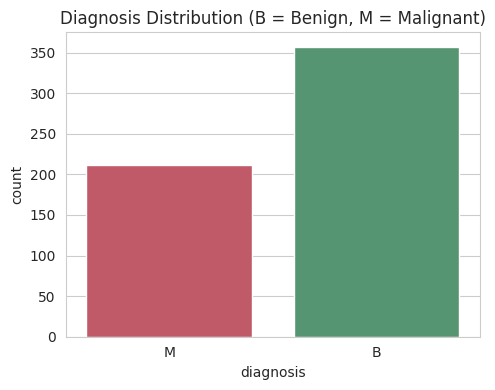

In [8]:
# Target class balance
plt.figure(figsize=(5, 4))
sns.countplot(x="diagnosis", data=df, palette={"B": "#4C9F70", "M": "#D1495B"})
plt.title("Diagnosis Distribution (B = Benign, M = Malignant)")
save_fig("lab3_target_distribution.png")

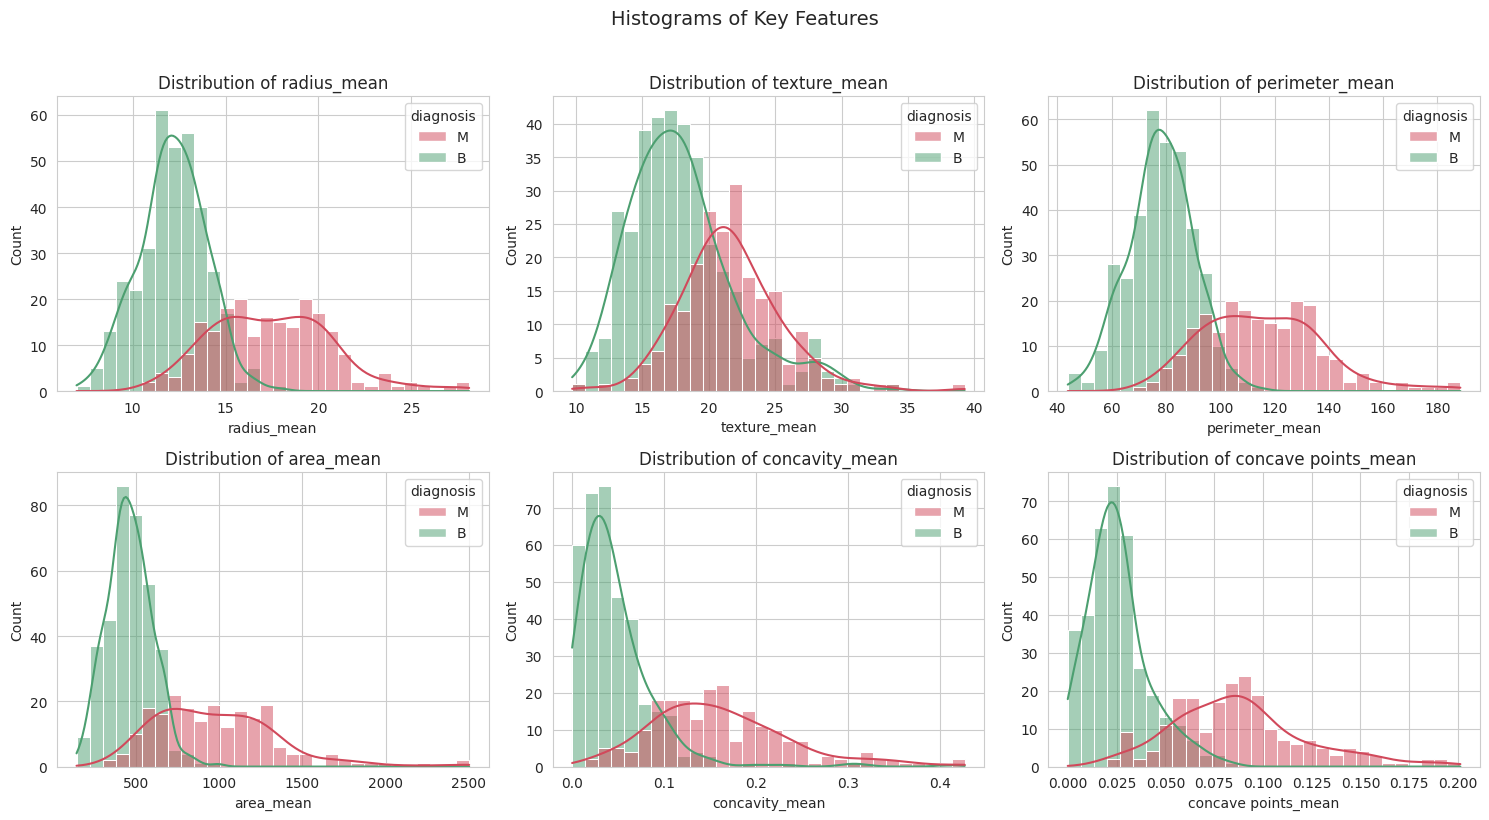

In [9]:
# Histograms of important features, split by diagnosis
key_features = [c for c in ["radius_mean", "texture_mean", "perimeter_mean", "area_mean",
                            "concavity_mean", "concave points_mean"] if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), key_features):
    sns.histplot(data=df, x=col, hue="diagnosis", kde=True, bins=30, ax=ax,
                 palette={"B": "#4C9F70", "M": "#D1495B"})
    ax.set_title(f"Distribution of {col}")
plt.suptitle("Histograms of Key Features", fontsize=14, y=1.02)
save_fig("lab3_histograms.png")

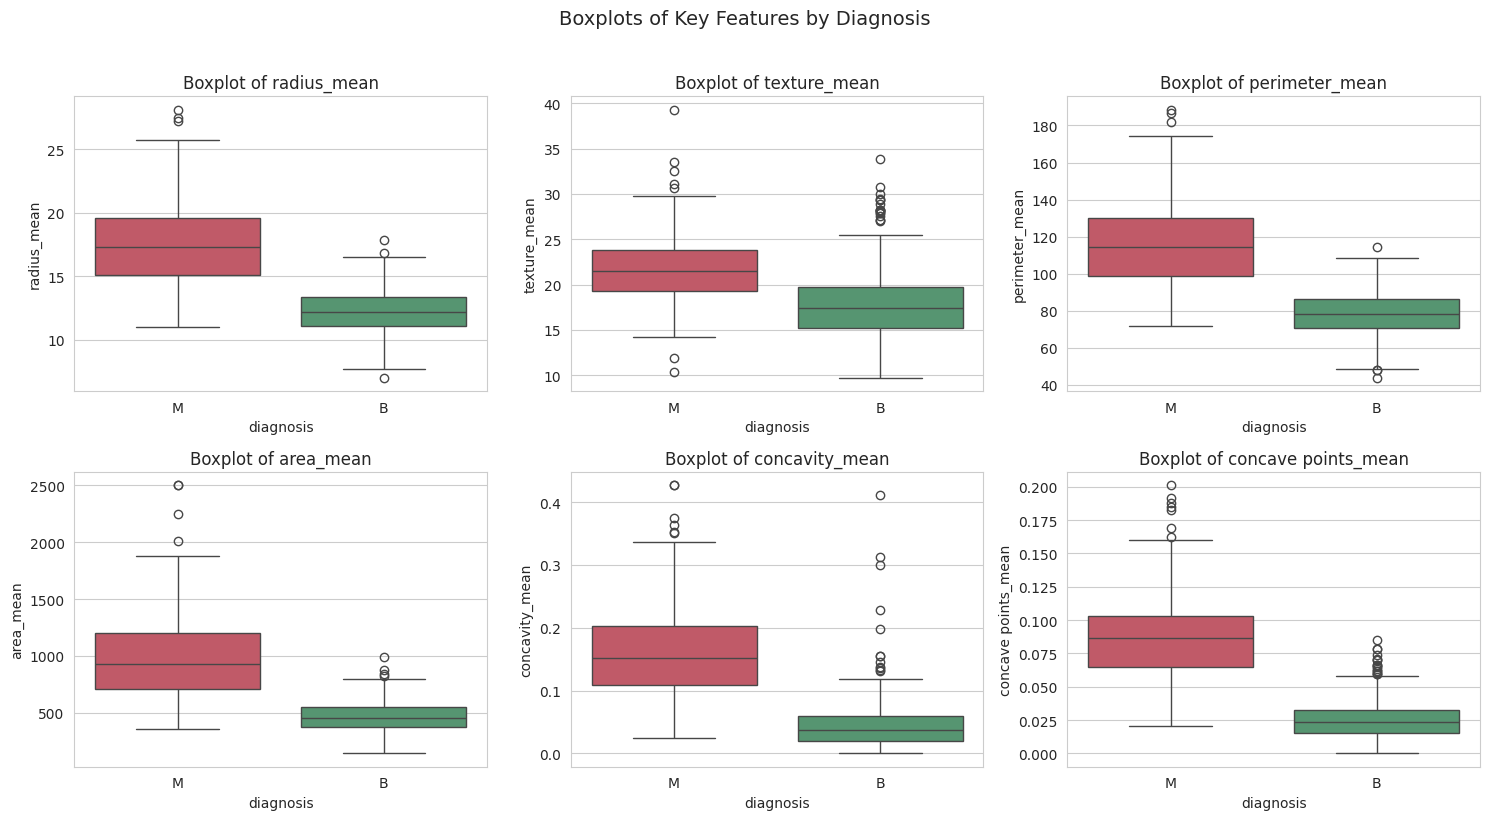

In [10]:
# Boxplots of important features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), key_features):
    sns.boxplot(data=df, x="diagnosis", y=col, ax=ax,
                palette={"B": "#4C9F70", "M": "#D1495B"})
    ax.set_title(f"Boxplot of {col}")
plt.suptitle("Boxplots of Key Features by Diagnosis", fontsize=14, y=1.02)
save_fig("lab3_boxplots.png")

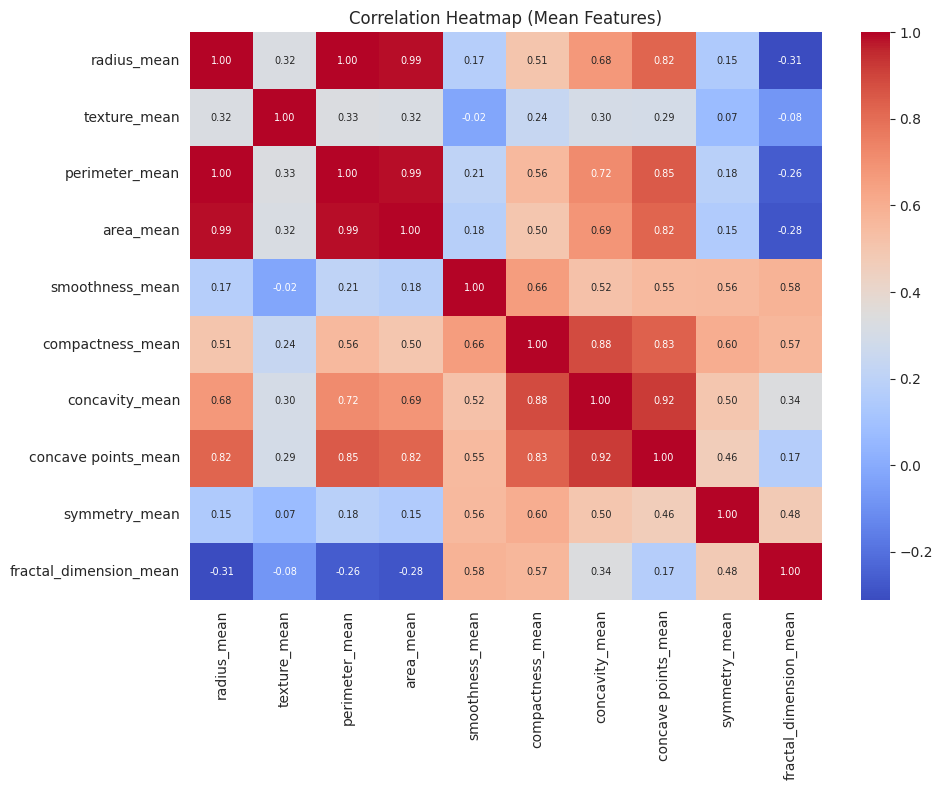

In [11]:
# Correlation heatmap of the "mean" features
mean_cols = [c for c in df.columns if c.endswith("_mean")]
plt.figure(figsize=(10, 8))
sns.heatmap(df[mean_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Correlation Heatmap (Mean Features)")
save_fig("lab3_correlation_heatmap.png")

## Task 2 – Data Preprocessing
Steps: drop useless columns → handle missing values → encode target → save cleaned CSV →
70/30 stratified split → feature scaling (StandardScaler, fitted on the training set only to avoid data leakage).

In [12]:
data = df.copy()

# 1. Drop the ID column and the empty 'Unnamed: 32' column (present in the Kaggle file)
drop_cols = [c for c in ["id", "Unnamed: 32"] if c in data.columns]
data = data.drop(columns=drop_cols)

# 2. Handle missing values (drop empty columns, fill remaining numeric NaNs with median)
data = data.dropna(axis=1, how="all")
num_cols = data.select_dtypes(include=np.number).columns
data[num_cols] = data[num_cols].fillna(data[num_cols].median())
data = data.drop_duplicates()

# 3. Encode categorical target: M -> 1 (Malignant), B -> 0 (Benign)
data["diagnosis"] = data["diagnosis"].map({"M": 1, "B": 0})

print("Missing values after cleaning:", int(data.isnull().sum().sum()))
print("Cleaned shape:", data.shape)

# 4. Save the cleaned dataset (deliverable)
data.to_csv("outputs/cleaned_breast_cancer.csv", index=False)
print("Saved: outputs/cleaned_breast_cancer.csv")

Missing values after cleaning: 0
Cleaned shape: (569, 31)
Saved: outputs/cleaned_breast_cancer.csv


In [13]:
# 5. Train / test split – 70% / 30%
X = data.drop(columns="diagnosis")
y = data["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# 6. Feature scaling (fit on train only)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Train: (398, 30) | Test: (171, 30)


## Helper functions for training & evaluation

In [14]:
results = {}        # name -> metrics dict
preds = {}          # name -> (y_pred, y_prob)


def evaluate_model(name, model):
    """Train the model, store metrics, predictions and probabilities."""
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)
    y_prob = model.predict_proba(X_test_s)[:, 1]
    cv = cross_val_score(model, X_train_s, y_train, cv=5, scoring="accuracy").mean()

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "CV Accuracy (5-fold)": cv,
    }
    preds[name] = (y_pred, y_prob)
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))


def plot_confusion(names, fname):
    n = len(names)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 4.2))
    axes = np.atleast_1d(axes)
    for ax, name in zip(axes, names):
        cm = confusion_matrix(y_test, preds[name][0])
        ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(
            ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(name)
    save_fig(fname)


def comparison_table(names=None):
    table = pd.DataFrame(results).T
    if names:
        table = table.loc[names]
    return table.round(4)

## Task 3 – Logistic Regression & Decision Tree

In [15]:
evaluate_model("Logistic Regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
evaluate_model("Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE))

=== Logistic Regression ===
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.98       107
   Malignant       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171

=== Decision Tree ===
              precision    recall  f1-score   support

      Benign       0.91      0.93      0.92       107
   Malignant       0.89      0.84      0.86        64

    accuracy                           0.90       171
   macro avg       0.90      0.89      0.89       171
weighted avg       0.90      0.90      0.90       171



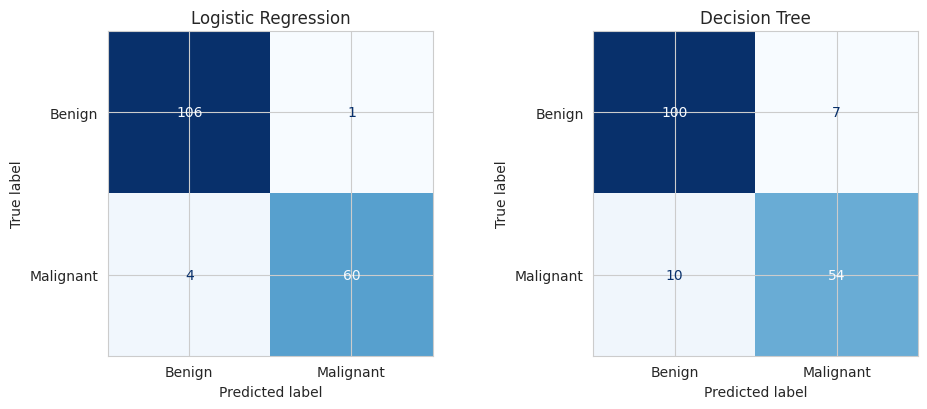

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Accuracy (5-fold)
Logistic Regression,0.9708,0.9836,0.9375,0.960,0.9975,0.9723
Decision Tree,0.9006,0.8852,0.8438,0.864,0.8892,0.9168


In [16]:
plot_confusion(["Logistic Regression", "Decision Tree"], "lab3_cm_task3.png")
comparison_table(["Logistic Regression", "Decision Tree"])

## Task 4 – Random Forest & Support Vector Machine

In [17]:
evaluate_model("Random Forest", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))
evaluate_model("SVM (RBF)", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))

=== Random Forest ===
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98       107
   Malignant       1.00      0.92      0.96        64

    accuracy                           0.97       171
   macro avg       0.98      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171

=== SVM (RBF) ===
              precision    recall  f1-score   support

      Benign       0.94      1.00      0.97       107
   Malignant       1.00      0.89      0.94        64

    accuracy                           0.96       171
   macro avg       0.97      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171



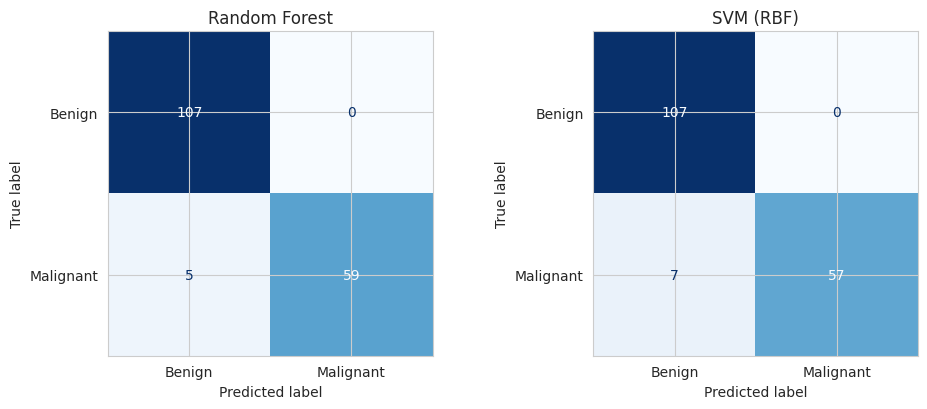

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Accuracy (5-fold)
Logistic Regression,0.9708,0.9836,0.9375,0.9600,0.9975,0.9723
Decision Tree,0.9006,0.8852,0.8438,0.8640,0.8892,0.9168
Random Forest,0.9708,1.0000,0.9219,0.9593,0.9958,0.9496
SVM (RBF),0.9591,1.0000,0.8906,0.9421,0.9972,0.9697


In [18]:
plot_confusion(["Random Forest", "SVM (RBF)"], "lab3_cm_task4.png")
comparison_table(["Logistic Regression", "Decision Tree", "Random Forest", "SVM (RBF)"])

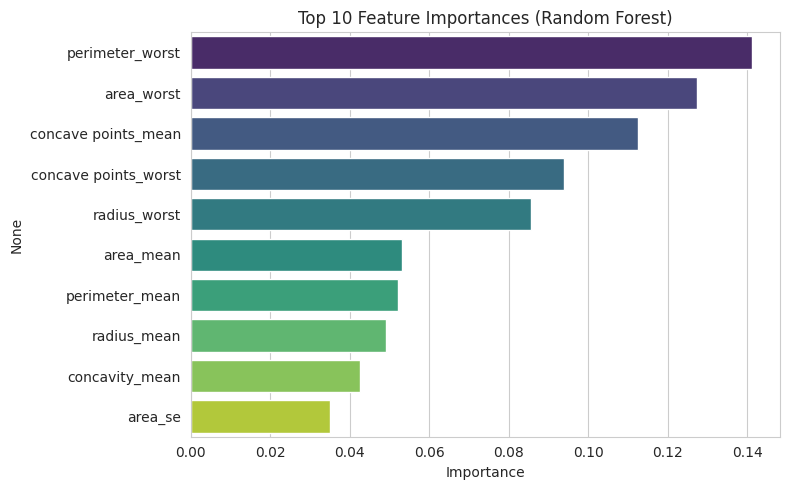

In [19]:
# Feature importance from Random Forest (top 10)
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE).fit(X_train_s, y_train)
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, palette="viridis")
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance")
save_fig("lab3_feature_importance.png")

## Task 5 – Naïve Bayes & Final Comparison of All Models

In [20]:
evaluate_model("Naive Bayes", GaussianNB())

=== Naive Bayes ===
              precision    recall  f1-score   support

      Benign       0.93      0.97      0.95       107
   Malignant       0.95      0.88      0.91        64

    accuracy                           0.94       171
   macro avg       0.94      0.92      0.93       171
weighted avg       0.94      0.94      0.94       171



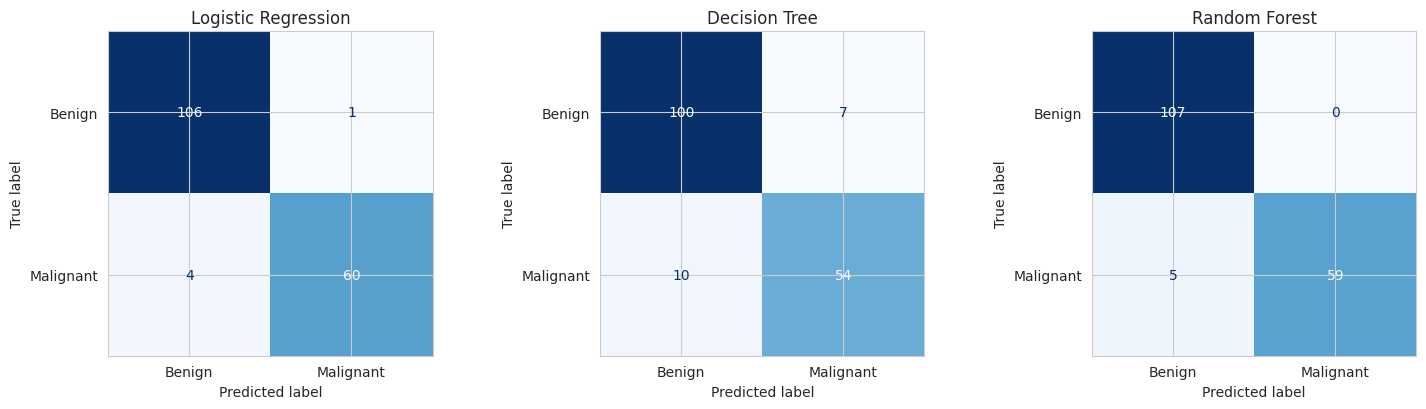

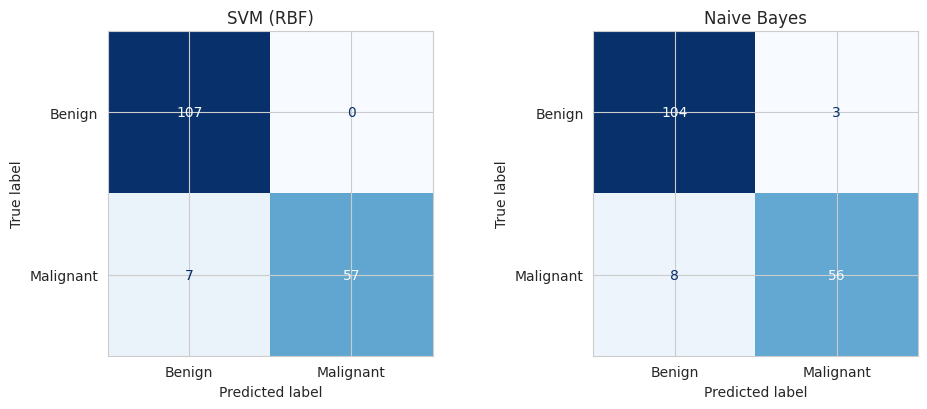

In [21]:
all_models = list(results.keys())
plot_confusion(all_models[:3], "lab3_cm_all_1.png")
plot_confusion(all_models[3:], "lab3_cm_all_2.png")

In [22]:
# Final comparison table
final_table = comparison_table().sort_values("F1-Score", ascending=False)
final_table.to_csv("outputs/lab3_model_comparison_report.csv")
final_table

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Accuracy (5-fold)
Logistic Regression,0.9708,0.9836,0.9375,0.9600,0.9975,0.9723
Random Forest,0.9708,1.0000,0.9219,0.9593,0.9958,0.9496
SVM (RBF),0.9591,1.0000,0.8906,0.9421,0.9972,0.9697
Naive Bayes,0.9357,0.9492,0.8750,0.9106,0.9933,0.9296
Decision Tree,0.9006,0.8852,0.8438,0.8640,0.8892,0.9168


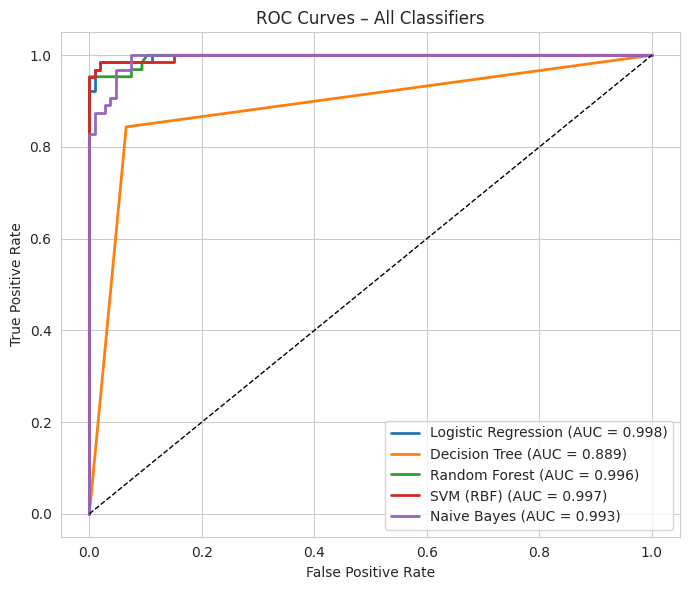

In [23]:
# ROC curves of all models
plt.figure(figsize=(7, 6))
for name in all_models:
    fpr, tpr, _ = roc_curve(y_test, preds[name][1])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves – All Classifiers")
plt.legend(loc="lower right")
save_fig("lab3_roc_curves.png")

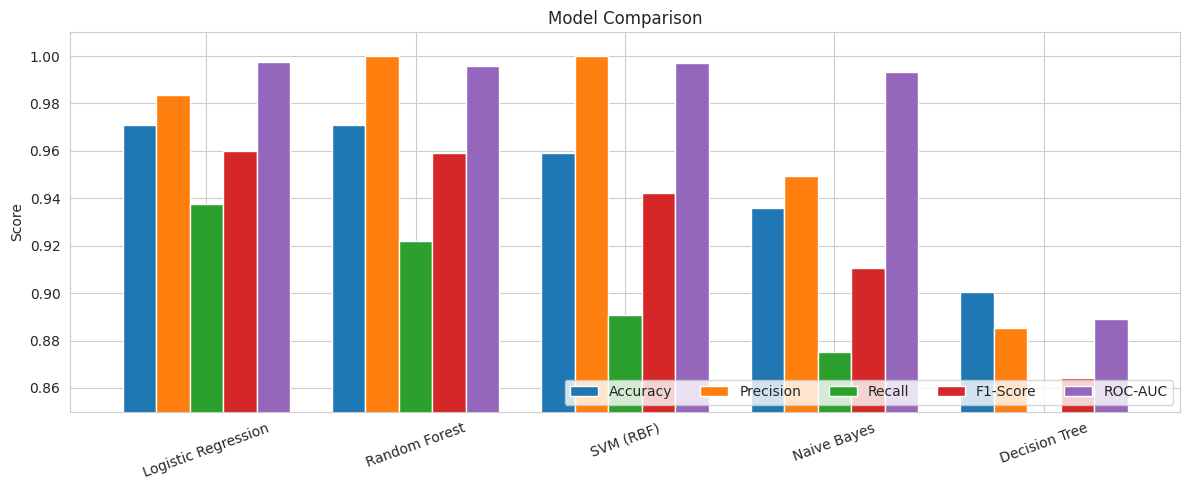

In [24]:
# Metric comparison bar chart
ax = final_table[["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(12, 5), width=0.8)
ax.set_ylim(0.85, 1.01)
ax.set_title("Model Comparison")
ax.set_ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right", ncol=5)
save_fig("lab3_model_comparison.png")

In [25]:
# Best model: in cancer diagnosis, missing a malignant tumor (False Negative) is the costliest error,
# so we rank by Recall first, then F1-Score and ROC-AUC.
best = final_table.sort_values(["Recall", "F1-Score", "ROC-AUC"], ascending=False).index[0]
print("Best model (Recall > F1 > ROC-AUC):", best)
print(final_table.loc[best])

tn, fp, fn, tp = confusion_matrix(y_test, preds[best][0]).ravel()
print(f"\nConfusion matrix of best model -> TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Best model (Recall > F1 > ROC-AUC): Logistic Regression
Accuracy                0.9708
Precision               0.9836
Recall                  0.9375
F1-Score                0.9600
ROC-AUC                 0.9975
CV Accuracy (5-fold)    0.9723
Name: Logistic Regression, dtype: float64

Confusion matrix of best model -> TN=106, FP=1, FN=4, TP=60


## Short Conclusion
In this lab, five classifiers (Logistic Regression, Decision Tree, Random Forest, SVM and Naive Bayes) were trained on the Breast Cancer Wisconsin dataset. The data was cleaned, the diagnosis was encoded (M = 1, B = 0), split into 70% training and 30% testing sets using stratification, and scaled with StandardScaler fitted only on the training data to avoid leakage. Logistic Regression gave the best overall performance with accuracy 0.971, precision 0.984, recall 0.938, F1-score 0.960 and ROC-AUC 0.998, producing only 4 false negative(s) and 1 false positive(s) on the test set. Decision Tree was the weakest model with an F1-score of 0.864, while the Decision Tree reached 0.864. Since missing a malignant tumor is far more harmful than a false alarm, recall was given the highest priority, followed by F1-score and ROC-AUC. The ROC curves and confusion matrices support this ranking. Therefore, Logistic Regression is recommended for accurate and reliable tumor prediction, and it should be validated further on larger external data before any real clinical use.
